# Session 10 · Reinforcement Learning Basics

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-10-reinforcement-learning-basics.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: the agent-environment loop and discounted return

In [1]:
"""A tiny corridor environment, a random policy and a smart policy, and the discounted return."""
import numpy as np

class Corridor:
    """States 0..5. Start at 0. Reaching 5 gives +10 and ends the episode. Each step costs -1."""
    def __init__(self, length=6):
        self.length = length
    def reset(self):
        self.s = 0
        return self.s
    def step(self, action):                       # action: 0 = left, 1 = right
        self.s = max(0, min(self.length - 1, self.s + (1 if action == 1 else -1)))
        done = self.s == self.length - 1
        return self.s, (10 if done else -1), done

def run(policy, env, gamma=0.9, seed=0, max_steps=200):
    rng = np.random.default_rng(seed)
    s, rewards = env.reset(), []
    for _ in range(max_steps):
        s, r, done = env.step(policy(s, rng))
        rewards.append(r)
        if done:
            break
    G = sum(gamma ** t * r for t, r in enumerate(rewards))
    return len(rewards), sum(rewards), G

env = Corridor()
random_policy = lambda s, rng: rng.integers(2)
right_policy = lambda s, rng: 1
for name, pol in [("random", random_policy), ("always right", right_policy)]:
    stats = np.array([run(pol, env, seed=k) for k in range(200)])
    print(f"{name:<13} avg steps {stats[:, 0].mean():6.1f}  avg total reward {stats[:, 1].mean():7.1f}  avg discounted return {stats[:, 2].mean():6.2f}")

rewards = [-1, -1, -1, -1, 10]
for g in [0.0, 0.5, 0.9, 1.0]:
    print(f"gamma = {g:<4} -> return of the optimal episode = {sum(g ** t * r for t, r in enumerate(rewards)):6.2f}")

random        avg steps   31.5  avg total reward   -20.5  avg discounted return  -6.20
always right  avg steps    5.0  avg total reward     6.0  avg discounted return   3.12
gamma = 0.0  -> return of the optimal episode =  -1.00
gamma = 0.5  -> return of the optimal episode =  -1.25
gamma = 0.9  -> return of the optimal episode =   3.12
gamma = 1.0  -> return of the optimal episode =   6.00


### Example 2 · Intermediate: four bandit strategies and regret

strategy         regret after 1000  found best arm


greedy                       299.5             8%


eps-greedy 0.1                66.0            64%


UCB (c=1)                     89.6            86%


Thompson                      38.6            85%


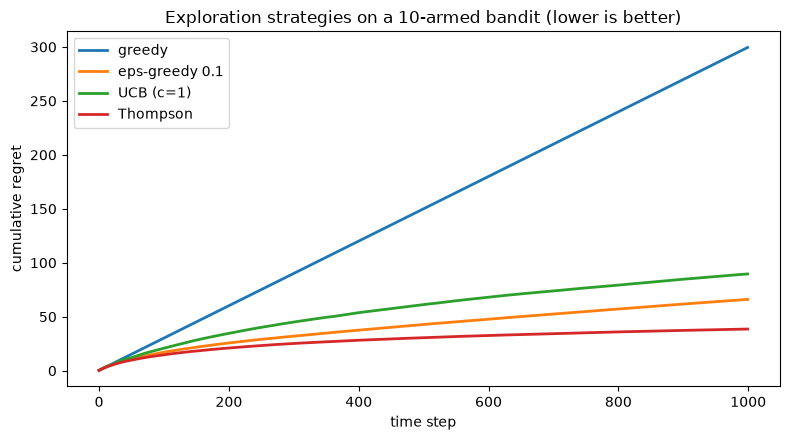

In [2]:
"""10-armed bandit: greedy, epsilon-greedy, UCB and Thompson sampling, averaged over 200 runs."""
import numpy as np
import matplotlib.pyplot as plt

K, T, RUNS = 10, 1000, 200
def run(strategy, seed):
    rng = np.random.default_rng(seed)
    p = rng.uniform(0.1, 0.9, K)                     # true click rates of 10 ad designs (unknown)
    Q, N = np.zeros(K), np.zeros(K)
    a_s, b_s = np.ones(K), np.ones(K)                # Beta(1,1) priors for Thompson
    regret, best = np.zeros(T), p.max()
    for t in range(T):
        if strategy == "greedy":
            a = int(np.argmax(Q))
        elif strategy == "eps-greedy 0.1":
            a = rng.integers(K) if rng.random() < .1 else int(np.argmax(Q))
        elif strategy == "UCB (c=1)":
            a = t if t < K else int(np.argmax(Q + np.sqrt(np.log(t + 1) / N)))
        else:                                        # Thompson sampling
            a = int(np.argmax(rng.beta(a_s, b_s)))
        r = float(rng.random() < p[a])
        N[a] += 1; Q[a] += (r - Q[a]) / N[a]
        a_s[a] += r; b_s[a] += 1 - r
        regret[t] = best - p[a]
    return regret.cumsum(), np.argmax(N) == np.argmax(p)

strategies = ["greedy", "eps-greedy 0.1", "UCB (c=1)", "Thompson"]
plt.figure(figsize=(8, 4.5))
print(f"{'strategy':<16}{'regret after 1000':>18}{'found best arm':>16}")
for s in strategies:
    out = [run(s, k) for k in range(RUNS)]
    reg = np.mean([o[0] for o in out], axis=0); found = np.mean([o[1] for o in out])
    print(f"{s:<16}{reg[-1]:>18.1f}{found:>15.0%}")
    plt.plot(reg, label=s, lw=2)
plt.xlabel("time step"); plt.ylabel("cumulative regret"); plt.title("Exploration strategies on a 10-armed bandit (lower is better)")
plt.legend(); plt.tight_layout(); plt.savefig("session-10_bandit_regret.png", dpi=110); plt.show()

### Example 3 · Intermediate: reward design and reward hacking

In [3]:
"""Same Q-learning agent, three reward functions on a 6x6 grid: sparse, step penalty, and a hackable bonus."""
import numpy as np

SIZE, GOAL, COIN = 6, (5, 5), (0, 2)
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]

def step(s, a):
    r, c = s[0] + MOVES[a][0], s[1] + MOVES[a][1]
    return (min(max(r, 0), SIZE - 1), min(max(c, 0), SIZE - 1))

def reward(design, s, s2):
    if design == "sparse":
        return 1.0 if s2 == GOAL else 0.0
    if design == "step penalty":
        return 10.0 if s2 == GOAL else -1.0
    # 'hackable': +2 every time the agent stands on a coin square that never runs out
    return 10.0 if s2 == GOAL else (2.0 if s2 == COIN else -1.0)

def train(design, episodes=1500, alpha=.5, gamma=.95, eps=.2, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((SIZE, SIZE, 4))
    for _ in range(episodes):
        s = (0, 0)
        for _ in range(100):
            a = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s]))
            s2 = step(s, a); r = reward(design, s, s2)
            target = r if s2 == GOAL else r + gamma * Q[s2].max()
            Q[s][a] += alpha * (target - Q[s][a]); s = s2
            if s == GOAL:
                break
    # evaluate greedy policy
    s, path = (0, 0), [(0, 0)]
    for _ in range(40):
        s = step(s, int(np.argmax(Q[s]))); path.append(s)
        if s == GOAL:
            break
    return path

for design in ["sparse", "step penalty", "hackable"]:
    path = train(design)
    reached = path[-1] == GOAL
    coin_visits = sum(p == COIN for p in path)
    print(f"{design:<13} reached goal: {reached!s:<5}  steps: {len(path) - 1:>2}  coin visits: {coin_visits}")

sparse        reached goal: False  steps: 40  coin visits: 0
step penalty  reached goal: True   steps: 10  coin visits: 0


hackable      reached goal: False  steps: 40  coin visits: 39


### Example 4 · Advanced: Monte Carlo, SARSA and Q-learning on Cliff Walking

SARSA        average return (last 100 episodes, while exploring):   -25.2
greedy path learned by SARSA:
>>>>>>>>>>v.
^.........v.
^.........>v
^CCCCCCCCCCG



Q-learning   average return (last 100 episodes, while exploring):   -46.6
greedy path learned by Q-learning:
............
............
>>>>>>>>>>>v
^CCCCCCCCCCG



Monte Carlo  average return (last 100 episodes, while exploring):   -38.6


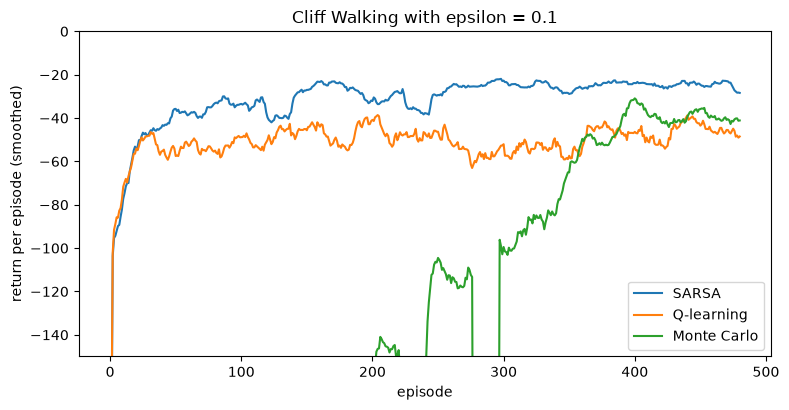

In [4]:
"""Cliff Walking: SARSA (on-policy) vs Q-learning (off-policy) vs Monte Carlo control, learning curves and paths."""
import numpy as np
import matplotlib.pyplot as plt

H, W = 4, 12
START, GOAL = (3, 0), (3, 11)
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]           # up, right, down, left
ARROWS = "^>v<"

def env_step(s, a):
    r, c = min(max(s[0] + MOVES[a][0], 0), H - 1), min(max(s[1] + MOVES[a][1], 0), W - 1)
    if r == 3 and 0 < c < 11:
        return START, -100, False                     # fell off the cliff
    return (r, c), -1, (r, c) == GOAL

def policy(Q, s, eps, rng):
    return rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s]))

def train(method, episodes=500, alpha=.5, gamma=1.0, eps=.1, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((H, W, 4)); returns = []
    for _ in range(episodes):
        s, a, total, traj = START, None, 0, []
        a = policy(Q, s, eps, rng)
        for _ in range(500):
            s2, r, done = env_step(s, a)
            a2 = policy(Q, s2, eps, rng)
            total += r
            if method == "SARSA":
                Q[s][a] += alpha * (r + gamma * Q[s2][a2] * (not done) - Q[s][a])
            elif method == "Q-learning":
                Q[s][a] += alpha * (r + gamma * Q[s2].max() * (not done) - Q[s][a])
            else:
                traj.append((s, a, r))
            s, a = s2, a2
            if done:
                break
        if method == "Monte Carlo":                   # every-visit MC update at the end of the episode
            G = 0
            for (st, at, rt) in reversed(traj):
                G = rt + gamma * G
                Q[st][at] += 0.05 * (G - Q[st][at])
        returns.append(total)
    return Q, np.array(returns)

def greedy_path(Q):
    grid = [["." for _ in range(W)] for _ in range(H)]
    for c in range(1, 11): grid[3][c] = "C"
    s = START
    for _ in range(40):
        a = int(np.argmax(Q[s])); grid[s[0]][s[1]] = ARROWS[a]
        s, _, done = env_step(s, a)
        if done or s == START: break
    grid[3][11] = "G"
    return "\n".join("".join(row) for row in grid)

plt.figure(figsize=(8, 4.2))
for method in ["SARSA", "Q-learning", "Monte Carlo"]:
    runs = [train(method, seed=k) for k in range(10)]
    curve = np.mean([r for _, r in runs], axis=0)
    smooth = np.convolve(curve, np.ones(20) / 20, mode="valid")
    print(f"{method:<12} average return (last 100 episodes, while exploring): {curve[-100:].mean():7.1f}")
    plt.plot(smooth, label=method)
    if method != "Monte Carlo":
        print(f"greedy path learned by {method}:\n{greedy_path(runs[0][0])}\n")
plt.ylim(-150, 0); plt.xlabel("episode"); plt.ylabel("return per episode (smoothed)")
plt.title("Cliff Walking with epsilon = 0.1"); plt.legend()
plt.tight_layout(); plt.savefig("session-10_cliff_learning.png", dpi=110); plt.show()

### 🏙️ Real-life data problem: choosing the best push-notification message

method                    orders   regret   share of traffic per message
A/B test (uniform)          1054    390.0   [0.2 0.2 0.2 0.2 0.2]


Thompson (one model)        1238    174.2   [0.04 0.78 0.11 0.06 0.01]


Thompson (contextual)       1269    140.3   [0.03 0.71 0.1  0.12 0.04]

best single message overall: 20% off biryani
best for students: 20% off biryani | best for families: Your favourites are waiting


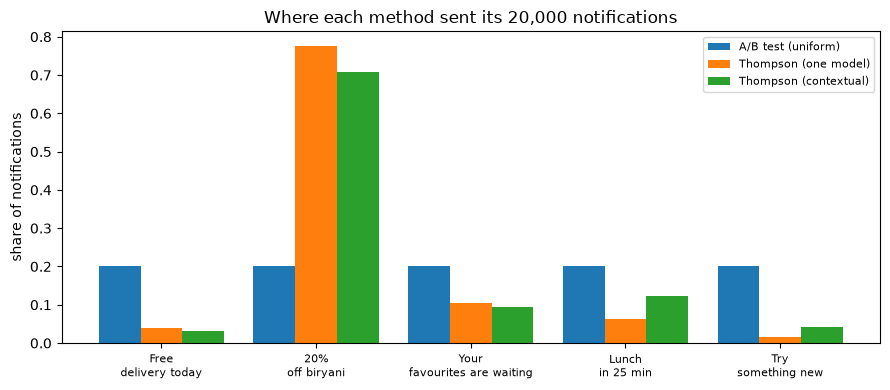

In [5]:
"""Real-life problem: push-notification optimisation with Thompson sampling vs a fixed A/B test (plus context)."""
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
messages = ["Free delivery today", "20% off biryani", "Your favourites are waiting", "Lunch in 25 min", "Try something new"]
rate = {"student": np.array([.050, .072, .030, .061, .040]),        # true conversion rates (unknown)
        "family":  np.array([.048, .055, .066, .040, .035])}
USERS = 20000
segments = rng.choice(["student", "family"], USERS, p=[.55, .45])

def simulate(method):
    a_s = {g: np.ones(5) for g in rate}; b_s = {g: np.ones(5) for g in rate}
    shown = np.zeros(5, int); orders = 0; regret = 0
    for i, g in enumerate(segments):
        ctx = g if method == "Thompson (contextual)" else "student"        # non-contextual: one shared model
        if method == "A/B test (uniform)":
            a = i % 5
        else:
            a = int(np.argmax(rng.beta(a_s[ctx], b_s[ctx])))
        r = rng.random() < rate[g][a]
        a_s[ctx][a] += r; b_s[ctx][a] += 1 - r
        shown[a] += 1; orders += r; regret += rate[g].max() - rate[g][a]
    return orders, regret, shown

print(f"{'method':<24}{'orders':>8}{'regret':>9}   share of traffic per message")
results = {}
for m in ["A/B test (uniform)", "Thompson (one model)", "Thompson (contextual)"]:
    o, reg, shown = simulate(m)
    results[m] = shown / USERS
    print(f"{m:<24}{o:>8}{reg:>9.1f}   {np.round(shown / USERS, 2)}")

best_all = (rate["student"] * .55 + rate["family"] * .45)
print("\nbest single message overall:", messages[int(best_all.argmax())])
print("best for students:", messages[int(rate['student'].argmax())], "| best for families:", messages[int(rate['family'].argmax())])

x = np.arange(5)
plt.figure(figsize=(9, 4))
for k, (m, share) in enumerate(results.items()):
    plt.bar(x + (k - 1) * .27, share, width=.27, label=m)
plt.xticks(x, [m.replace(" ", "\n", 1) for m in messages], fontsize=8); plt.ylabel("share of notifications")
plt.title("Where each method sent its 20,000 notifications"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("session-10_push_traffic.png", dpi=110); plt.show()

### 🧩 Mini project: a warehouse robot that learns to deliver

In [6]:
"""Mini project: Q-learning robot in a warehouse grid with shelves, a charging penalty and a delivery goal."""
import numpy as np

layout = ["S....#....",
          ".##..#.##.",
          ".#.......#",
          ".#.###.#..",
          "....#..#.D"]
H, W = len(layout), len(layout[0])
MOVES = {"up": (-1, 0), "down": (1, 0), "left": (0, -1), "right": (0, 1)}
names = list(MOVES)
start = next((r, c) for r in range(H) for c in range(W) if layout[r][c] == "S")
dock = next((r, c) for r in range(H) for c in range(W) if layout[r][c] == "D")

def step(s, a):
    dr, dc = MOVES[names[a]]
    r, c = s[0] + dr, s[1] + dc
    if not (0 <= r < H and 0 <= c < W) or layout[r][c] == "#":
        return s, -5, False                       # bumped into a shelf or wall
    if (r, c) == dock:
        return (r, c), 50, True
    return (r, c), -1, False

rng = np.random.default_rng(0)
Q = np.zeros((H, W, 4))
alpha, gamma = 0.3, 0.95
for ep in range(3000):
    eps = max(0.02, 1 - ep / 1500)
    s = start
    for _ in range(200):
        a = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s]))
        s2, r, done = step(s, a)
        Q[s][a] += alpha * (r + gamma * Q[s2].max() * (not done) - Q[s][a])
        s = s2
        if done:
            break
    if ep in (0, 500, 1500, 2999):
        print(f"after episode {ep:>4}: value of start state = {Q[start].max():6.2f}")

grid = [list(row) for row in layout]
s, steps = start, 0
while s != dock and steps < 50:
    a = int(np.argmax(Q[s]))
    if s != start:
        grid[s[0]][s[1]] = "^v<>"[a]
    s, _, _ = step(s, a); steps += 1
print(f"\ngreedy route found in {steps} moves:")
print("\n".join("".join(row) for row in grid))

after episode    0: value of start state =  -0.51


after episode  500: value of start state =  17.83
after episode 1500: value of start state =  17.83


after episode 2999: value of start state =  17.83

greedy route found in 13 moves:
S>>v.#....
.##v.#.##.
.#.>>>>>v#
.#.###.#v.
....#..#>D
